RFP-02 | Lake Interior NoData Trial

1. Design basis

Test an interpretation of RFP-02 MR-02 in which LiDAR and RGB are required over all terrestrial areas, including islands, and RGB is also required across a water-side shoreline band. PR-04 permits documented LiDAR voids over open water, and MR-07 excludes bathymetry. The RGB NoData mask applies at delivery. The aircraft may still cross open water in transit, and imagery acquired incidentally beyond the shoreline band can still be masked in the final product.

Use the original flat-reference geometry and the same camera, LiDAR, battery and speed settings from rfp02_config.py. The coastline and island trace are approximate. Land outside that trace but inside the RFP polygon is treated as required. At 80 m the modeled RGB combined swath is about 191 m wide and its conservative along-track frame length is about 52 m. The shoreline band starts at one planned strip spacing plus one photo interval's travel (42 m at nominal settings). This is an adjustable planning allowance to provide water-side context and some tolerance for the traced shore. It is not an RFP-mandated width or a positional-accuracy claim.

Requires the existing environment and rfp02_config.py in the same folder. Run All. Outputs are written to lake_nodata_outputs/ independently of the baseline mission.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.path import Path as PlotPath
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from IPython.display import display

import rfp02_config as cfg

photo_step = cfg.rgb_photo_interval_s * cfg.survey_speed_mps
shore_band_m = cfg.line_spacing_m + photo_step
grid_m = cfg.coverage_grid_m
step_margin = np.sqrt(2) * grid_m
rgb_half_length = cfg.rgb_min_along_m / 2
lidar_half_width = cfg.lidar_width_m / 2
rgb_half_width = cfg.rgb_combined_width_m / 2
out = Path("lake_nodata_outputs")
out.mkdir(exist_ok=True)

2. Required areas and route trimming

Use the same 5 m grid as the baseline. Measure the water-side buffer from both the lake shoreline and the island perimeter. For each heading, start with the original flight strips. Keep the parts of each strip that contribute to either sensor's required area, including neighbouring flight lines whose footprints reach it. Preserve the baseline number of intersecting strips per required cell for the same heading and direction. This is a redundancy proxy. The along-track RGB rectangles use the first and last trigger and the conservative minimum footprint. Continuous swath overlap is checked geometrically; image matching, return density and positional accuracy require separate evidence.

When trimming, round the needed intervals outward on the grid and retain extra run-in/out and trigger distance at cut ends. Merge close intervals. Test both a 50 m split threshold and a threshold where faster transit offsets the modeled turn delay. For each heading and direction, include the untrimmed route in the search. It can use the same delivery mask if shorter collection does not improve the schedule. The solver still prices every connector and return leg.

In [2]:
x0, y0 = cfg.corners.min(axis=0)
x1, y1 = cfg.corners.max(axis=0)
x, y = np.meshgrid(np.arange(x0 + grid_m / 2, x1, grid_m),
                   np.arange(y0 + grid_m / 2, y1, grid_m))
all_pts = np.column_stack((x.ravel(), y.ravel()))
points = all_pts[PlotPath(cfg.corners).contains_points(all_pts)]
lake = PlotPath(cfg.lake_xy).contains_points(points)
island = PlotPath(cfg.island_xy).contains_points(points)
land = ~lake | island

def edge_distance(points, boundary):
    nearest = np.full(len(points), np.inf)
    for a, b in zip(boundary, np.roll(boundary, -1, axis=0)):
        dx, dy = b - a
        px, py = (points - a).T
        scale = np.clip((px * dx + py * dy) / (dx**2 + dy**2), 0, 1)
        nearest = np.minimum(nearest, np.hypot(px - scale * dx, py - scale * dy))
    return nearest

water_distance = np.minimum(edge_distance(points, cfg.lake_xy),
                            edge_distance(points, cfg.island_xy))
shore = ~land & (water_distance <= shore_band_m)
rgb_target = land | shore
masked = ~rgb_target
print(f"Water-side RGB band: {shore_band_m:.0f} m | NoData area: {masked.sum()*grid_m**2/1e6:.3f} km²")

def projected(points, start, unit):
    dx, dy = (points - start).T
    return dx * unit[0] + dy * unit[1], dx * unit[1] - dy * unit[0]

def crop_route(grid, minimum_gap):
    pieces = []
    for start, end in grid:
        delta = end - start
        length = np.linalg.norm(delta)
        unit = delta / length
        along, cross = projected(points, start, unit)
        lidar = land & (np.abs(cross) <= lidar_half_width + step_margin)
        rgb = rgb_target & (np.abs(cross) <= rgb_half_width + step_margin)
        # Include the original RGB frame overhang when deciding what to protect.
        lidar &= (along >= 0) & (along <= length)
        rgb &= (along >= -rgb_half_length) & (along <= length + rgb_half_length)
        support = along[lidar | rgb]
        if not len(support):
            continue
        stations = np.unique(np.floor(np.clip(support, 0, length) / grid_m))
        chunks = np.split(stations, np.flatnonzero(np.diff(stations) > 1) + 1)
        padding = step_margin + photo_step + cfg.run_in_out_m
        windows = []
        for chunk in chunks:
            left = max(0, chunk[0] * grid_m - padding)
            right = min(length, (chunk[-1] + 1) * grid_m + padding)
            if windows and left - windows[-1][1] < minimum_gap:
                windows[-1][1] = right
            else:
                windows.append([left, right])
        pieces.extend([start + np.array([[a], [b]]) * unit for a, b in windows if b > a])
    return np.asarray(pieces)

def count_coverage(route):
    lidar = np.zeros(len(points), dtype=np.uint16)
    rgb = np.zeros_like(lidar)
    for start, end in route:
        delta = end - start
        length = np.linalg.norm(delta)
        along, cross = projected(points, start, delta / length)
        cross = np.abs(cross)
        lidar += (cross <= lidar_half_width) & (along >= 0) & (along <= length)
        last_trigger = (np.ceil(length / photo_step) - 1) * photo_step
        rgb += ((cross <= rgb_half_width) & (along >= -rgb_half_length)
                & (along <= last_trigger + rgb_half_length))
    return lidar, rgb

Water-side RGB band: 42 m | NoData area: 1.044 km²


In [3]:
seconds_saved_per_m = 1 / cfg.survey_speed_mps - 1 / cfg.transit_speed_mps
economic_gap = 60 * cfg.turn_delay_min / seconds_saved_per_m if seconds_saved_per_m > 0 else np.inf
gap_options = {"Trim ≥50 m": 50, "Trim time-positive gaps": max(50, economic_gap)}
candidates = []
rejected = 0
for bearing in cfg.bearings_deg:
    grid = cfg.scan_grid(bearing, cfg.line_spacing_m)
    if cfg.cross_grid:
        grid = np.concatenate((grid, cfg.scan_grid(bearing + 90, cfg.line_spacing_m)))
    cropped = {policy: crop_route(grid, gap) for policy, gap in gap_options.items()}
    for reverse in (False, True):
        baseline = grid[::-1, ::-1] if reverse else grid
        base_lidar, base_rgb = count_coverage(baseline)
        candidates.append((bearing, reverse, "Full grid", baseline))
        for policy, forward in cropped.items():
            if not len(forward) or np.array_equal(forward, grid):
                continue
            route = forward[::-1, ::-1] if reverse else forward
            lidar, rgb = count_coverage(route)
            if (np.any(lidar[land] < np.maximum(base_lidar[land], 1))
                or np.any(rgb[rgb_target] < np.maximum(base_rgb[rgb_target], 1))):
                rejected += 1
                continue
            if not any(b == bearing and r == reverse and np.array_equal(route, other)
                       for b, r, _, other in candidates):
                candidates.append((bearing, reverse, policy, route))
print(f"{len(candidates)} route candidates retained; {rejected} failed the coverage/redundancy screen.")

51 route candidates retained; 21 failed the coverage/redundancy screen.


3. Compare all launch sites

Rank each site's routes first by field days, then by field minutes. The NoData case can choose the original route or a trimmed one. The boat proxy and disabled sites follow the existing launch-site selection settings. The detailed time-based simulation below uses LZ-01 for a direct comparison to the previous mission.

In [4]:
def score_routes(site_id):
    site = cfg.sites[site_id]
    fixed = (cfg.access_minutes(site) + cfg.setup_packdown_min + cfg.survey_control_min_per_day
             + cfg.delay_allowance_min_per_day + cfg.site_daily_extra_min.get(site_id, 0))
    options = []
    for bearing, reverse, policy, route in candidates:
        times, reach = cfg.sortie_times(route, site, cfg.airborne_endurance_min, cfg.c2_slant_limit_m)
        if times is None:
            continue
        result = cfg.schedule(times, fixed)
        if result is not None:
            options.append(dict(result=result, bearing=bearing, reverse=reverse, policy=policy,
                                route=route, reach=reach))
    baseline = min((p for p in options if p["policy"] == "Full grid"),
                   key=lambda p: p["result"][:2], default=None)
    # Break exact time ties in favor of a simpler untrimmed route.
    best = min(options, key=lambda p: (*p["result"][:2], p["policy"] != "Full grid"), default=None)
    return baseline, best

comparison, site_plans = [], {}
for site_id in cfg.sites:
    baseline, best = score_routes(site_id)
    site_plans[site_id] = (baseline, best)
    eligible = site_id not in cfg.disabled_sites and (site_id != cfg.boat_id or cfg.include_boat_in_selection)
    for case, plan in (("Full-area baseline", baseline), ("NoData trial", best)):
        row = {"Site": site_id, "Location": cfg.site_names[site_id], "Case": case, "Eligible": eligible}
        if plan is not None:
            route = plan["route"]
            days, mins, schedule = plan["result"]
            row.update(Policy=plan["policy"], Days=days, **{"Field min": mins,
                       "Airborne min": sum(t for day in schedule for _, _, t in day),
                       "Sorties": sum(map(len, schedule)),
                       "Survey km": np.linalg.norm(route[:, 1] - route[:, 0], axis=1).sum()/1000,
                       "Bearing deg": plan["bearing"], "Max slant km": plan["reach"]/1000})
        comparison.append(row)
results = pd.DataFrame(comparison)
display(results.round(2))
results.to_csv(out / "launch_site_comparison.csv", index=False)
ranked = results.loc[results.Eligible & (results.Case == "NoData trial")].dropna(subset=["Days"])
if len(ranked):
    print("Fastest eligible site:", ranked.sort_values(["Days", "Field min"]).iloc[0].Site)

site_id = cfg.parking_id
baseline, plan = site_plans[site_id]
if plan is None:
    raise ValueError("LZ-01 has no feasible schedule under these settings.")
base = cfg.sites[site_id].xy
route = plan["route"]
field_days, total_min, schedule = plan["result"]
print(f"LZ-01: {plan['policy']}, {len(route)} acquisition segments.")

,Site,Location,Case,Eligible,Policy,Days,Field min,Airborne min,Sorties,Survey km,Bearing deg,Max slant km
0,LZ-01,Hwy 37 parking lot,Full-area baseline,True,Full grid,1,369.93,200.93,7,95.59,120,2.36
1,LZ-01,Hwy 37 parking lot,NoData trial,True,Trim time-positive gaps,1,368.97,199.97,7,84.22,120,2.36
2,LZ-02,Trail 25%,Full-area baseline,True,Full grid,1,378.68,197.32,7,95.59,120,2.12
3,LZ-02,Trail 25%,NoData trial,True,Trim time-positive gaps,1,377.72,196.36,7,84.22,120,2.12
4,LZ-03,Trail 50%,Full-area baseline,True,Full grid,1,388.73,195.00,7,95.59,120,1.91
5,LZ-03,Trail 50%,NoData trial,True,Trim time-positive gaps,1,387.77,194.04,7,84.22,120,1.91
6,LZ-04,Trail 75%,Full-area baseline,True,Full grid,1,402.67,196.57,7,95.59,120,1.75
7,LZ-04,Trail 75%,NoData trial,True,Trim time-positive gaps,1,391.76,192.66,6,84.22,120,1.75
8,LZ-05,Trail terminus,Full-area baseline,True,Full grid,1,406.50,195.04,6,95.36,15,1.75
9,LZ-05,Trail terminus,NoData trial,True,Trim time-positive gaps,1,402.04,190.58,6,82.42,15,1.75


Fastest eligible site: LZ-01
LZ-01: Trim time-positive gaps, 87 acquisition segments.


4. Simulate the selected LZ-01 route

Build the full timeline with the established flight and ground activity model. LiDAR and RGB are active on each retained acquisition segment. Connectors, including open-water crossings, are charged as flight with the payload off. The altitude is the flat planning altitude. Flight-day totals and each sortie are checked against the optimizer.

In [5]:
segments, photo_events, sortie_rows = [], [], []

def add_segment(phase, start, end, duration_s, z0=0, z1=0, strip=None):
    t0 = segments[-1]["end_s"] if segments else 0.0
    segments.append(dict(day=day, sortie=sortie, phase=phase, start_s=t0, end_s=t0 + duration_s,
                         east_start_m=start[0], north_start_m=start[1], height_start_m=z0,
                         east_end_m=end[0], north_end_m=end[1], height_end_m=z1,
                         distance_m=np.linalg.norm(end - start), strip=strip,
                         lidar_on=phase == "Survey", rgb_enabled=phase == "Survey"))
    if phase == "Survey":
        for offset in np.arange(0, duration_s, cfg.rgb_photo_interval_s):
            position = start + offset / duration_s * (end - start)
            photo_events.append((day, sortie, strip, t0 + offset, *position, z0, 2))

def fly(phase, start, end, speed, strip=None):
    height = cfg.flight_height_above_base_m
    add_segment(phase, start, end, np.linalg.norm(end - start) / speed, height, height, strip)

for day, day_plan in enumerate(schedule, 1):
    sortie = 0
    add_segment("Setup and checks", base, base, 30 * cfg.setup_packdown_min)
    add_segment("Survey control", base, base, 60 * cfg.survey_control_min_per_day)
    for sortie, (first, stop, optimizer_min) in enumerate(day_plan, 1):
        takeoff = segments[-1]["end_s"]
        first_event = len(segments)
        height = cfg.flight_height_above_base_m
        add_segment("Climb", base, base, cfg.climb_descent_min * 30, 0, height)
        fly("Outbound transit", base, route[first, 0], cfg.transit_speed_mps)
        for i in range(first, stop):
            start, end = route[i]
            if i > first:
                previous = route[i - 1, 1]
                add_segment("Turn", previous, previous, 60 * cfg.turn_delay_min, height, height)
                fly("Reposition", previous, start, cfg.transit_speed_mps)
            fly("Survey", start, end, cfg.survey_speed_mps, i + 1)
        fly("Return transit", route[stop - 1, 1], base, cfg.transit_speed_mps)
        add_segment("Descent", base, base, cfg.climb_descent_min * 30, height, 0)
        landing = segments[-1]["end_s"]
        actual_min = (landing - takeoff) / 60
        assert np.isclose(optimizer_min, actual_min)
        assert actual_min <= cfg.usable_flight_min + 1e-9
        legs = segments[first_event:]
        sortie_rows.append((day, sortie, first + 1, stop, takeoff / 60, landing / 60, actual_min,
                            cfg.usable_flight_min - actual_min, sum(s["distance_m"] for s in legs) / 1000))
        add_segment("Turnaround and data QA", base, base, 60 * cfg.turnaround_min)
    sortie = 0
    add_segment("Delay allowance", base, base, 60 * cfg.delay_allowance_min_per_day)
    add_segment("Packdown", base, base, 30 * cfg.setup_packdown_min)
    extra = cfg.site_daily_extra_min.get(site_id, 0)
    if extra:
        add_segment("Site allowance", base, base, 60 * extra)

timeline = pd.DataFrame(segments)
photos = pd.DataFrame(photo_events, columns=["day", "sortie", "strip", "time_s", "east_m", "north_m",
                                             "height_m", "images"])
sorties = pd.DataFrame(sortie_rows, columns=["Day", "Sortie", "First strip", "Last strip",
                                            "Takeoff min", "Landing min", "Airborne min", "Margin min",
                                            "Horizontal km"])
assert site_id == cfg.parking_id and cfg.access_minutes(cfg.sites[site_id]) == 0
assert np.isclose(timeline.end_s.iloc[-1] / 60, total_min)
assert np.allclose(timeline.end_s.iloc[:-1], timeline.start_s.iloc[1:])
for axis in ("east", "north", "height"):
    assert np.allclose(timeline[f"{axis}_end_m"].iloc[:-1], timeline[f"{axis}_start_m"].iloc[1:])
acquisition = timeline.loc[timeline.lidar_on]
assert acquisition.strip.tolist() == list(range(1, len(route) + 1))
display(sorties.round(2))
sorties.to_csv(out / "sortie_schedule.csv", index=False)
timeline.to_csv(out / "mission_timeline.csv", index=False)
photos.to_csv(out / "rgb_triggers.csv", index=False)

,Day,Sortie,First strip,Last strip,Takeoff min,Landing min,Airborne min,Margin min,Horizontal km
0,1,1,1,13,77.50,110.37,32.87,0.88,18.06
1,1,2,14,23,117.37,148.03,30.66,3.09,16.70
2,1,3,24,37,155.03,185.71,30.68,3.07,16.71
3,1,4,38,49,192.71,212.25,19.55,14.20,10.53
4,1,5,50,61,219.25,239.60,20.34,13.41,10.68
5,1,6,62,77,246.60,278.98,32.38,1.37,17.68
6,1,7,78,87,285.98,319.47,33.49,0.26,18.41


5. Coverage audit and route comparison

Audit LiDAR over land and RGB over land plus the water-side band. As a resolution check, repeat the audit on a half-cell-shifted grid. The shaded NoData area is an output mask. It does not show where a sensor happened to collect incidental data. The planning screen does not resolve shoreline-trace error, terrain, canopy, or navigation accuracy.

,Grid,Required coverage,Cells,Uncovered,Minimum intersecting strips
0,Design grid,Land LiDAR,62248,0,2
1,Design grid,Land + shoreline RGB,73396,0,3
2,Shifted grid,Land LiDAR,62247,0,2
3,Shifted grid,Land + shoreline RGB,73419,0,3


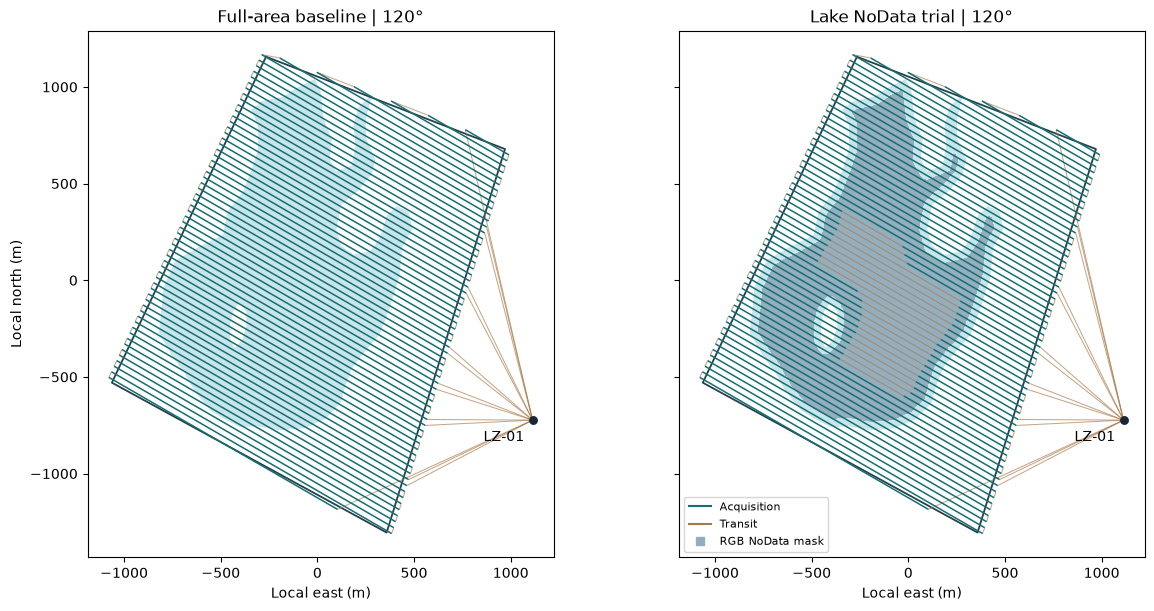

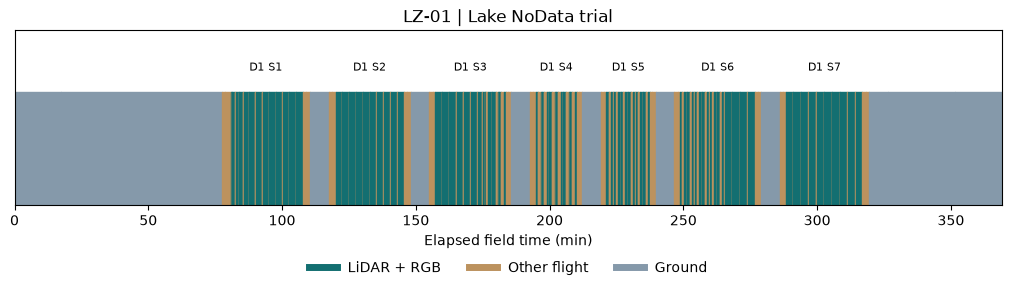

LZ-01 | 369.9 → 369.0 field min; 1.0 min saved.
84.22 km acquisition; 108.77 km total flight.
7 sorties; 0.26 min tightest margin above reserve.


In [6]:
coverage_rows = []
for grid_name, shift in (("Design grid", 0), ("Shifted grid", grid_m / 2)):
    audit_x, audit_y = np.meshgrid(np.arange(x0 + grid_m/2 + shift, x1, grid_m),
                                   np.arange(y0 + grid_m/2 + shift, y1, grid_m))
    audit_points = np.column_stack((audit_x.ravel(), audit_y.ravel()))
    audit_points = audit_points[PlotPath(cfg.corners).contains_points(audit_points)]
    audit_land = ~PlotPath(cfg.lake_xy).contains_points(audit_points) | PlotPath(cfg.island_xy).contains_points(audit_points)
    distance = np.minimum(edge_distance(audit_points, cfg.lake_xy), edge_distance(audit_points, cfg.island_xy))
    audit_rgb = audit_land | (distance <= shore_band_m)
    # Reuse the footprint calculation on this independently placed grid.
    design_points = points
    try:
        points = audit_points
        lidar_counts, rgb_counts = count_coverage(route)
    finally:
        points = design_points
    for label, target, counts in (("Land LiDAR", audit_land, lidar_counts),
                                  ("Land + shoreline RGB", audit_rgb, rgb_counts)):
        coverage_rows.append((grid_name, label, target.sum(), (target & (counts == 0)).sum(),
                              counts[target].min()))
audit = pd.DataFrame(coverage_rows, columns=["Grid", "Required coverage", "Cells", "Uncovered",
                                             "Minimum intersecting strips"])
display(audit)
audit.to_csv(out / "coverage_audit.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 6), layout="constrained", sharex=True, sharey=True)
for ax, item, title in zip(axes, (baseline, plan), ("Full-area baseline", "Lake NoData trial")):
    ax.fill(*cfg.lake_xy.T, color="#c8e5ec")
    ax.fill(*cfg.island_xy.T, color="#fffdf6")
    ax.plot(*cfg.polygon.T, color="#283f4c", lw=1.3)
    ax.scatter(*base, c="#172735", s=29, zorder=5)
    ax.annotate(site_id, base, xytext=(-6, -15), textcoords="offset points", ha="right")
    if item is plan:
        ax.scatter(*points[masked].T, s=3, color="#95aebd", marker="s", lw=0)
    paths = item["route"]
    connectors = []
    for day in item["result"][2]:
        for first, stop, _ in day:
            connectors.extend([(base, paths[first, 0]), (paths[stop-1, 1], base)])
            connectors.extend(zip(paths[first:stop-1, 1], paths[first+1:stop, 0]))
    ax.add_collection(LineCollection(connectors, colors="#a77847", lw=0.75, alpha=0.65))
    ax.add_collection(LineCollection(paths, colors="#136f71", lw=1.1))
    ax.set(title=f"{title} | {item['bearing']}°", aspect="equal", xlabel="Local east (m)")
axes[0].set_ylabel("Local north (m)")
axes[1].legend(handles=[Line2D([], [], color="#136f71", label="Acquisition"),
                        Line2D([], [], color="#a77847", label="Transit"),
                        Line2D([], [], color="#95aebd", marker="s", lw=0, label="RGB NoData mask")],
               loc="lower left", fontsize=8)
fig.savefig(out / "route_comparison.png", dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(10, 2.8), layout="constrained")
phase_colors = {"Survey": "#136f71", "Turn": "#bc925e", "Reposition": "#bc925e",
                "Outbound transit": "#bc925e", "Return transit": "#bc925e",
                "Climb": "#bc925e", "Descent": "#bc925e"}
for event in timeline.itertuples():
    ax.broken_barh([(event.start_s/60, (event.end_s-event.start_s)/60)], (0, 0.65),
                   color=phase_colors.get(event.phase, "#8599aa"))
for start, end, day, sortie in sorties[["Takeoff min","Landing min","Day","Sortie"]].itertuples(index=False, name=None):
    ax.text((start+end)/2, 0.77, f"D{day} S{sortie}", ha="center", fontsize=8)
ax.set(xlim=(0, total_min), ylim=(0, 1), yticks=[], xlabel="Elapsed field time (min)",
       title="LZ-01 | Lake NoData trial")
ax.legend(handles=[Line2D([], [], color=color, lw=5, label=label) for color, label in
                 [("#136f71", "LiDAR + RGB"), ("#bc925e", "Other flight"), ("#8599aa", "Ground")]],
          loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3, frameon=False)
fig.savefig(out / "mission_timeline.png", dpi=180)
plt.show()

baseline_min = baseline["result"][1]
survey_km = timeline.loc[timeline.lidar_on, "distance_m"].sum() / 1000
print(f"LZ-01 | {baseline_min:.1f} → {total_min:.1f} field min; {baseline_min-total_min:.1f} min saved.")
print(f"{survey_km:.2f} km acquisition; {timeline.distance_m.sum()/1000:.2f} km total flight.")
print(f"{len(sorties)} sorties; {sorties['Margin min'].min():.2f} min tightest margin above reserve.")